# Paper figures (v2)

Regenerates all paper figures with the changes from the figure-reflection
document:

- **All figures**: titles removed (content moves to captions)
- **F1**: legend repositioned to upper right, friendly policy names
- **F3**: phase names instead of DWD codes on y-axis
- **F4**: phase names on y-axis, short x-axis labels
- **F5**: friendly panel subtitles ("Phase-resolved attention", etc.),
  phase names rotated 90° on x-axis, colorbar matched to plot height
- **F6**: shortened y-axis label, phase names rotated on x-axis
- **F8 (new)**: example LSTM probability curves for four representative fields

Also note: **F8 requires per-day logits** to be saved separately. If the file
`phase3_outputs/lstm/lstm_logits.npz` does not yet exist, F8 will be skipped
gracefully. Run the F8 add-on cell (`f8_save_logits_addon.py`) in a fresh
Jupyter session first to produce it.


## 1. Setup

In [10]:
from pathlib import Path
import sys
PROJECT_ROOT = Path('/fs1/home/atikul/Phenology')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Make sure we pick up the latest figures module rather than a cached version
import importlib, figures, figures.figures, figures.style
importlib.reload(figures.style)
importlib.reload(figures.figures)
importlib.reload(figures)

import matplotlib
matplotlib.use('Agg')   # no display needed; we save to file

from figures import make_all


## 2. Generate all figures

In [11]:
results = make_all(
    data_dir=PROJECT_ROOT,
    output_dir=PROJECT_ROOT / 'phase6_figures',
)
print()
print(results.to_string(index=False))


F1: wrote F1_hgb_streams.pdf and F1_hgb_streams.png
F2: wrote F2_hgb_vs_lstm.pdf and F2_hgb_vs_lstm.png
F3: wrote F3_lstm_phase_heatmap.pdf and F3_lstm_phase_heatmap.png
F4: wrote F4_supervision_winrate.pdf and F4_supervision_winrate.png
F5: wrote F5_attention_heatmap.pdf and F5_attention_heatmap.png
F6: wrote F6_cloud_conditional.pdf and F6_cloud_conditional.png
F8: wrote F8_example_curves.pdf and F8_example_curves.png
F9: wrote F9_loyo_stability.pdf and F9_loyo_stability.png

figure status
    F1     ok
    F2     ok
    F3     ok
    F4     ok
    F5     ok
    F6     ok
    F8     ok
    F9     ok


## 3. Inline preview


--- F1_hgb_streams.png ---


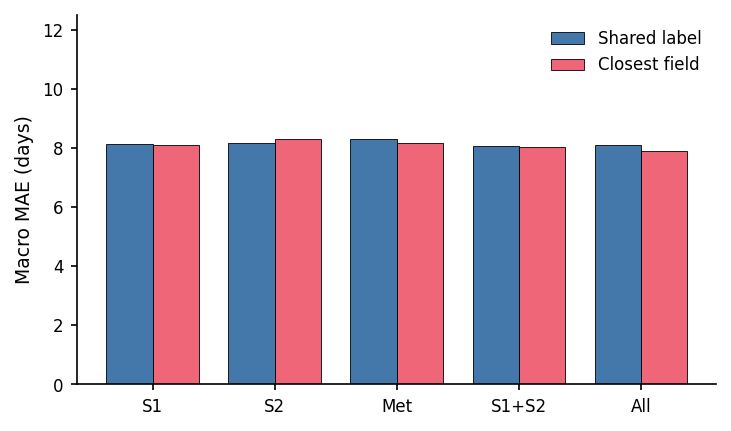


--- F2_hgb_vs_lstm.png ---


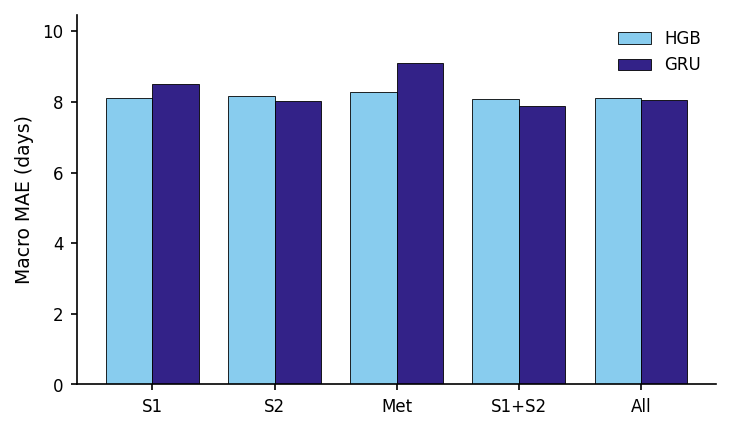


--- F3_lstm_phase_heatmap.png ---


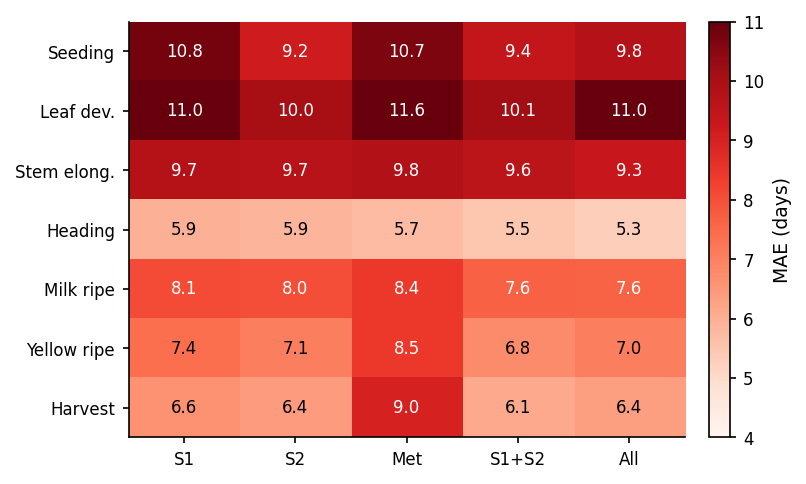


--- F4_supervision_winrate.png ---


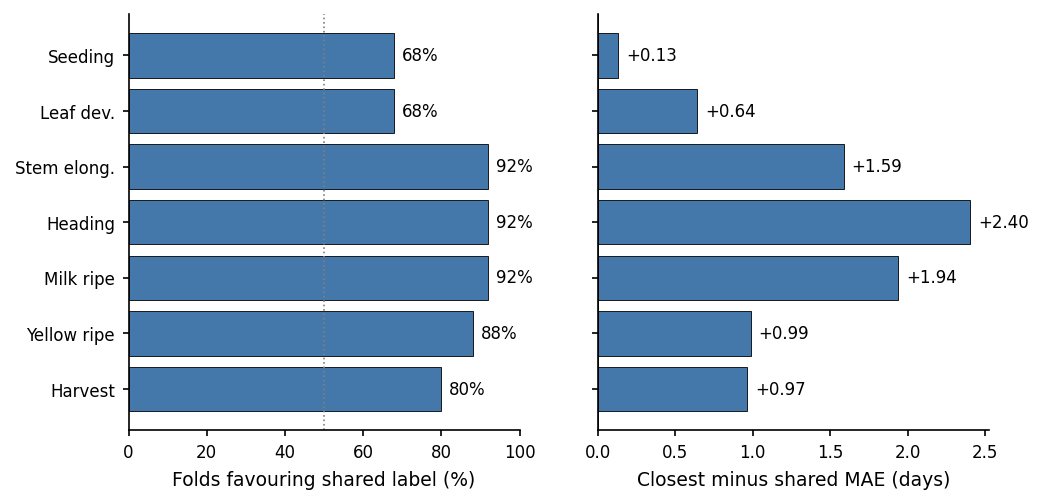


--- F5_attention_heatmap.png ---


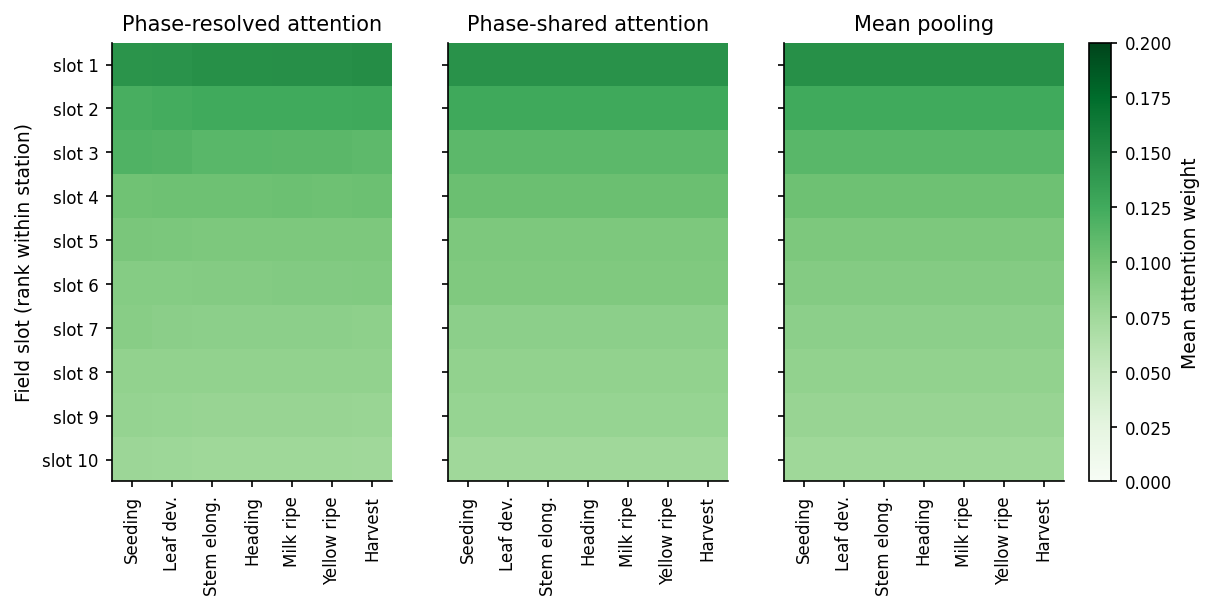


--- F6_cloud_conditional.png ---


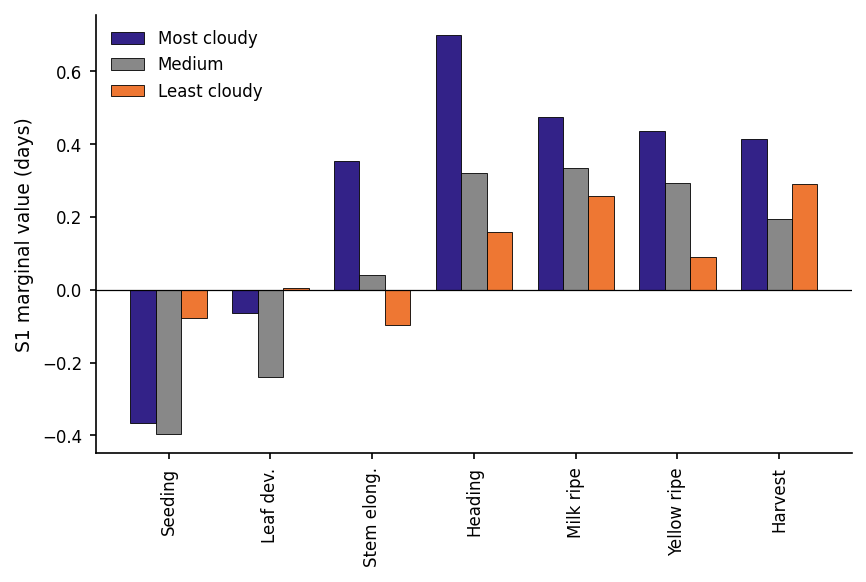


--- F8_example_curves.png ---


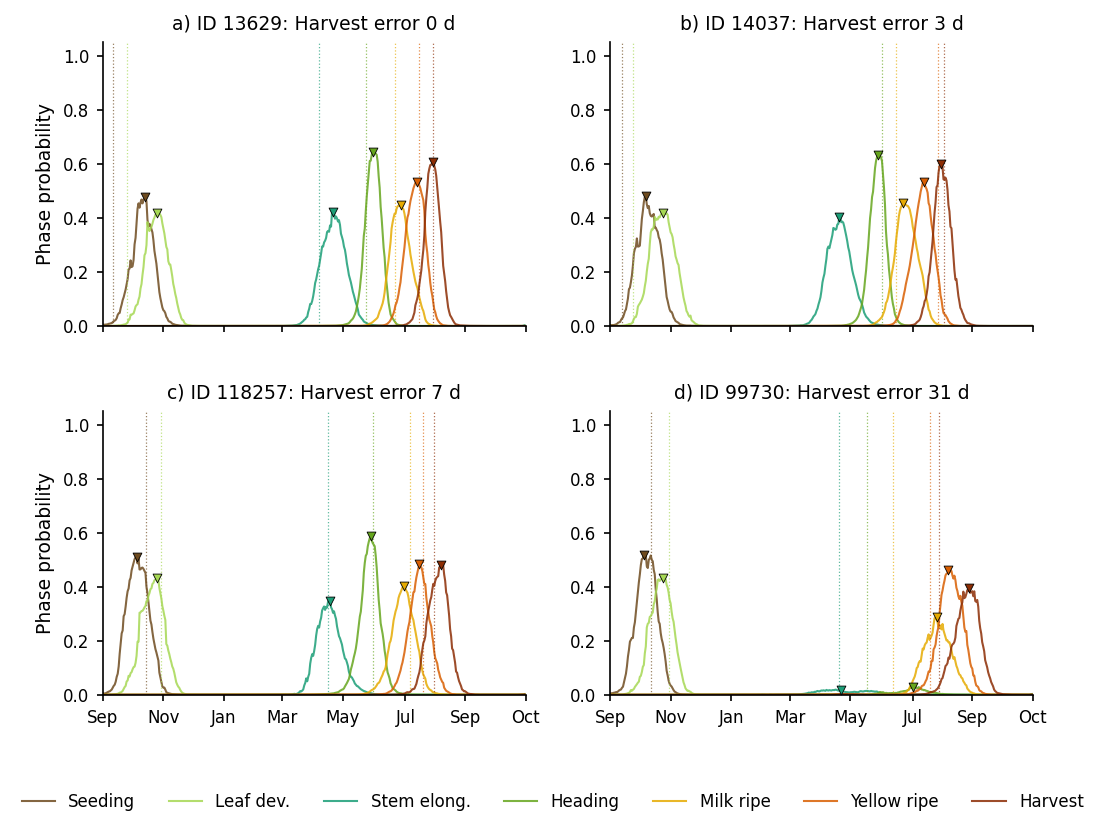


--- F9_loyo_stability.png ---


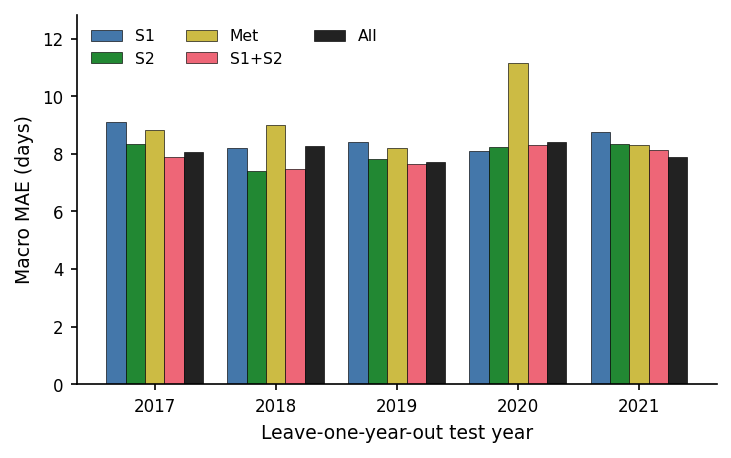

In [12]:
from IPython.display import Image, display
fig_dir = PROJECT_ROOT / 'phase6_figures'
for png in sorted(fig_dir.glob('*.png')):
    print(f'\n--- {png.name} ---')
    display(Image(filename=str(png), width=700))


## 4. Tweak a single figure

In [ ]:
# If a specific figure needs adjustment, edit figures/figures.py and
# regenerate just that one without rerunning the whole set.
import importlib, figures.figures
importlib.reload(figures.figures)
from figures.style import apply_style
from figures.figures import fig5_attention_heatmap   # change function name as needed
apply_style()
fig5_attention_heatmap(PROJECT_ROOT, PROJECT_ROOT / 'phase6_figures')


## Quick reference: where to tweak each figure

Each function lives in `figures/figures.py`. Common tweaks and where to find
them:

| Want to change... | Edit in `fig*_*` function |
|---|---|
| Colors | `colors`, `colors2`, `colors_strat` variables |
| Font sizes on tick labels | `set_xticklabels(..., fontsize=N)` calls |
| Bar widths | `w = 0.38` (or similar) |
| Y-axis labels | `ax.set_ylabel('...')` |
| Phase tick rotation | `rotation=90` keyword |
| Legend position | `ax.legend(loc='...')` |
| Figure size | `figsize=(w, h)` in `plt.subplots` |
| Colorbar position (F5) | The `cax = fig.add_axes([left, bottom, width, height])` line |
| Number of example fields (F8) | First arg to `axes = ...` and the `quantile_picks` list |
| Which phase F8 sorts by | `phase_to_plot` argument when calling |
| F8 fold year | `fold_year` argument |
